# RandomForest Classification Analysis with F-beta Score

This notebook trains a RandomForestClassifier on synthetic imbalanced data and performs analysis focusing on the F-beta score, which balances precision and recall according to the beta parameter.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import fbeta_score, precision_score, recall_score, precision_recall_curve, PrecisionRecallDisplay, classification_report

plt.style.use('seaborn-v0_8-whitegrid')

## Load Pre-split Training and Testing Data

We load the training and testing datasets

In [2]:
# Training and testing paths
train_csv_path = "../storage/datasets/dataset_train_2025-04-29-21-13-29.csv"
test_csv_path = "../storage/datasets/dataset_test_2025-04-29-21-13-29.csv"

# Load dataset
train_df = pd.read_csv(train_csv_path)
test_df = pd.read_csv(test_csv_path)

# Get features and target
y_train = train_df['is_fraud']
X_train = train_df.drop(columns=['is_fraud'])

y_test = test_df['is_fraud']
X_test = test_df.drop(columns=['is_fraud'])

# Drop Customer ID
X_train = X_train.drop(columns=['cc_num'], errors='ignore')
X_test = X_test.drop(columns=['cc_num'], errors='ignore')

# Display info
print(f"\nTraining set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"Training Features: {X_train.columns.tolist()}")


Training set shape: (26982, 13)
Testing set shape: (1350, 13)
Training Features: ['month_sin', 'month_cos', 'log_time_diff', 'amt_zscore', 'time_segment_daytime', 'time_segment_late_night', 'day_of_week_Friday', 'day_of_week_Monday', 'day_of_week_Saturday', 'day_of_week_Sunday', 'day_of_week_Thursday', 'day_of_week_Tuesday', 'day_of_week_Wednesday']


## Initialize Train and Predict RandomForest Model

Initializing Random Forest from sklearn, train and predict the model.

In [3]:
# Initialize Random Forrest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

# Train model
rf_model.fit(X_train, y_train)

# Predict class labels
y_pred = rf_model.predict(X_test)

# Predict probabilities
y_proba = rf_model.predict_proba(X_test)

# Get probabilities for positive class
y_scores = y_proba[:, 1]

## Calculate Standard & F-beta Scores

It calculates the precision and recall of the model's predictions compared to the true labels using a default classification threshold (implicitly 0.5). Then it iterates through a list of different beta values to calculate the F-beta score.

In [4]:
# Calculate standard metrics using default threshold predictions
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)

print("Metrics at Default Threshold (0.5)")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

# Calculate F-beta for multiple beta values
beta_values_to_test = [0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 5.0] # Test these beta values (now 8 values)
f_beta_results = []

for beta in beta_values_to_test:
    # Calculate F-beta score
    f_beta = fbeta_score(y_test, y_pred, beta=beta, zero_division=0)

    # Determine emphasis
    if beta < 1.0:
        emphasis = "Precision"
    elif beta == 1.0:
        emphasis = "Balanced (F1)"
    else: # beta > 1.0
        emphasis = "Recall"

    # Store results
    f_beta_results.append({
        'Beta': beta,
        'Emphasis': emphasis,
        'F-beta Score': f_beta
    })

Metrics at Default Threshold (0.5)
Precision: 0.9040
Recall: 0.7956


In [5]:
# Create and display DataFrame
if f_beta_results:
    summary_df = pd.DataFrame(f_beta_results)

    from IPython.display import display
    display(summary_df)

,Beta,Emphasis,F-beta Score
0,0.25,Precision,0.896846
1,0.50,Precision,0.880039
2,0.75,Precision,0.861737
3,1.00,Balanced (F1),0.846336
4,1.50,Recall,0.826056
5,2.00,Recall,0.815118
6,3.00,Recall,0.805218
7,5.00,Recall,0.799244


In [6]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Classification Report:
              precision    recall  f1-score   support

         0.0       0.96      0.98      0.97      1125
         1.0       0.90      0.80      0.85       225

    accuracy                           0.95      1350
   macro avg       0.93      0.89      0.91      1350
weighted avg       0.95      0.95      0.95      1350



## Plot Precision-Recall Curve

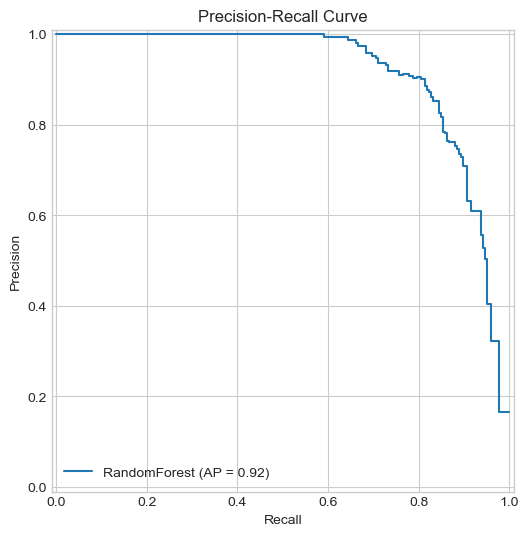

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
pr_display = PrecisionRecallDisplay.from_predictions(y_test, y_scores, name="RandomForest", ax=ax)
ax.set_title("Precision-Recall Curve")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
plt.show()

## Plot F-beta Score vs. Decision Threshold for Multiple Betas

It defines a list of `beta_values_to_plot`. Then, it calculates the precision, recall, and corresponding thresholds using the precision_recall_curve function based on the true labels and the model's prediction scores. Next, it prepares the data for plotting by filtering out potentially problematic initial points where precision or recall might be zero or very small.

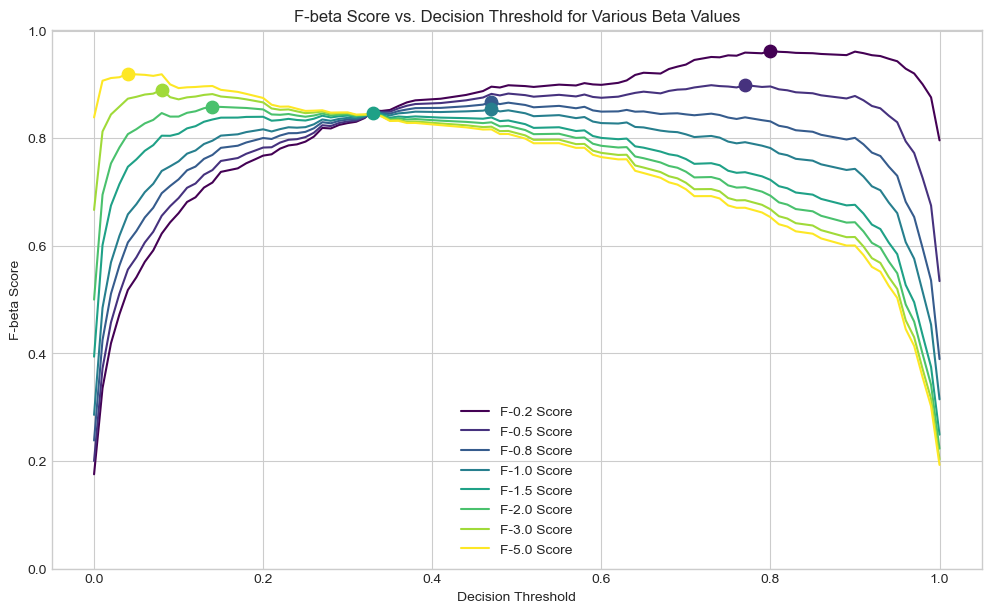

In [8]:
# List of beta values to plot
beta_values_to_plot = [0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 5.0]

# Calculate Precision, Recall, Thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_scores)

# Prepare data for plotting
valid_idx = (precisions > 1e-8) | (recalls > 1e-8)
precisions_valid = precisions[valid_idx][:-1]
recalls_valid = recalls[valid_idx][:-1]

# Thresholds list from precision_recall_curve has length n_thresholds
thresholds_valid = thresholds[:len(precisions_valid)]

# Plot
plt.figure(figsize=(12, 7))


points = {}

colors = plt.cm.viridis(np.linspace(0, 1, len(beta_values_to_plot))) # Get distinct colors

for i, beta in enumerate(beta_values_to_plot):
    # Calculate F-beta scores
    fbeta_scores = np.zeros_like(precisions_valid)
    denominator = (beta**2 * precisions_valid + recalls_valid)
    non_zero_den = denominator > 1e-8

    # Calculate score only where denominator is non-zero
    fbeta_scores[non_zero_den] = (1 + beta**2) * (precisions_valid[non_zero_den] * recalls_valid[non_zero_den]) / denominator[non_zero_den]

    # Find threshold that maximizes the current F-beta score
    if len(fbeta_scores) > 0:
        optimal_idx = np.argmax(fbeta_scores)
        optimal_threshold = thresholds_valid[optimal_idx]
        optimal_fbeta = fbeta_scores[optimal_idx]
        # Store optimal point details
        points[beta] = {
            'threshold': optimal_threshold,
            'f_score': optimal_fbeta,
            'precision': precisions_valid[optimal_idx],
            'recall': recalls_valid[optimal_idx]
        }
    else:
         points[beta] = {'threshold': 0.5, 'f_score': 0, 'precision': 0, 'recall': 0}
         print(f"Warning: No valid F-beta scores calculated for beta={beta:.1f}")

    # Plot curve for the current beta
    plt.plot(thresholds_valid, fbeta_scores, label=f'F-{beta:.1f} Score', color=colors[i])
    # Plot the optimal point for current beta
    plt.scatter(points[beta]['threshold'], points[beta]['f_score'], color=colors[i], marker='o', s=80, zorder=5, label=f'_nolegend_')

# Plot
plt.xlabel("Decision Threshold")
plt.ylabel("F-beta Score")
plt.title("F-beta Score vs. Decision Threshold for Various Beta Values")
plt.legend(loc='best')
plt.grid(True)
plt.ylim(bottom=0)
plt.show()

In [9]:
# Convert dictionary to DataFrame
summary_df = pd.DataFrame.from_dict(points, orient='index')

# Reset index
summary_df = summary_df.reset_index()

# Rename columns
summary_df = summary_df.rename(columns={
    'index': 'Beta',
    'threshold': 'Optimal Threshold',
    'f_score': 'Max F-beta Score',
    'precision': 'Precision at Opt',
    'recall': 'Recall at Opt'
})

summary_df

,Beta,Optimal Threshold,Max F-beta Score,Precision at Opt,Recall at Opt
0,0.25,0.80,0.962515,0.993151,0.644444
1,0.50,0.77,0.898673,0.986755,0.662222
2,0.75,0.47,0.867628,0.901478,0.813333
3,1.00,0.47,0.855140,0.901478,0.813333
4,1.50,0.33,0.846760,0.852018,0.844444
5,2.00,0.14,0.858586,0.708333,0.906667
6,3.00,0.08,0.889920,0.609827,0.937778
7,5.00,0.04,0.919669,0.503529,0.951111


## Plot F-beta Score vs. Beta Value

It takes a previously determined `optimal_threshold` and uses it to generate binary predictions from the model's continuous output scores. Any score greater than or equal to this fixed threshold is classified as 1, and the scores below are classified as 0. Then it defines an array of 100 evenly spaced `beta_values` ranging from 0.1 to 5.0. Finally, it iterates through each beta value in this array. For each beta, it calculates the F-beta score by comparing the true labels with the predictions made using the fixed threshold. The calculated F-beta score for each beta is then appended to the `f_scores_for_betas list`.

In [11]:
fixed_threshold = optimal_threshold
y_pred_fixed_thresh = (y_scores >= fixed_threshold).astype(int)

# Define a range of beta values to test
beta_values = np.linspace(0.1, 5.0, 100)

f_scores_for_betas = []
for beta in beta_values:
    score = fbeta_score(y_test, y_pred_fixed_thresh, beta=beta)
    f_scores_for_betas.append(score)

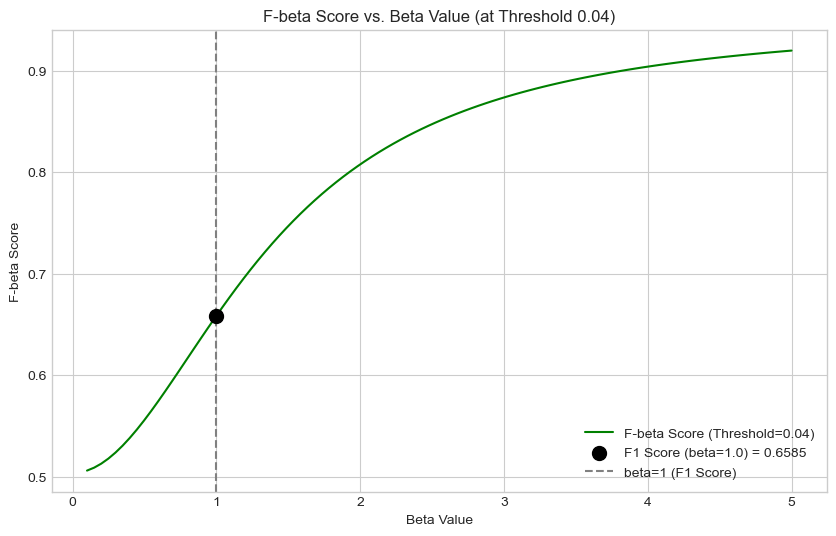

In [12]:
# Plot
plt.figure(figsize=(10, 6))
plt.plot(beta_values, f_scores_for_betas, label=f'F-beta Score (Threshold={fixed_threshold:.2f})', color='green')

f1_value_at_thresh = fbeta_score(y_test, y_pred_fixed_thresh, beta=1)
plt.scatter(1.0, f1_value_at_thresh, color='black', marker='o', s=100, zorder=5, label=f'F1 Score (beta=1.0) = {f1_value_at_thresh:.4f}')

plt.xlabel("Beta Value")
plt.ylabel("F-beta Score")
plt.title(f"F-beta Score vs. Beta Value (at Threshold {fixed_threshold:.2f})")
plt.axvline(1.0, color='grey', linestyle='--', label='beta=1 (F1 Score)')
plt.legend(loc='best')
plt.grid(True)
plt.show()